# Transformer Next-Token Prediction (from-scratch self-attention)

Character-level language model built **step by step** with explicit self-attention (no `nn.Transformer`, Hugging Face, or similar).

**Run in Google Colab** (recommended): enable GPU optional. After training, download the checkpoint and use the final section locally.

**Stack:** PyTorch for tensors and autograd only — attention, FFN, layer norm, and training loop are written explicitly.

## Step 0 — Colab setup

In [21]:
try:
    import google.colab  # type: ignore

    IN_COLAB = True
    %pip install -q torch matplotlib
except ImportError:
    IN_COLAB = False

import math
import random
import time
import urllib.request
import zipfile
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn as nn

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

Device: cuda


## Step 1 — Hyperparameters and reproducibility

GPU run uses mixed precision and `batch_size=128`. If you get CUDA OOM, change `batch_size` to `64` and re-run from Step 9.

In [22]:
@dataclass(frozen=True)
class TrainConfig:
    d_model: int = 256
    n_heads: int = 8
    n_layers: int = 6
    d_ff: int = 1024
    seq_len: int = 128
    batch_size: int = 128
    learning_rate: float = 3e-4
    weight_decay: float = 0.01
    log_interval_sec: int = 60
    eval_batches: int = 12
    seed: int = 42


CFG = TrainConfig()
assert CFG.d_model % CFG.n_heads == 0, "d_model must divide n_heads"

random.seed(CFG.seed)
torch.manual_seed(CFG.seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(CFG.seed)
    torch.backends.cudnn.benchmark = True

def project_root() -> Path:
    cwd = Path.cwd()
    if (cwd / "notebooks").is_dir() and (cwd / "requirements.txt").is_file():
        return cwd
    if (cwd.parent / "notebooks").is_dir():
        return cwd.parent
    return cwd


ARTIFACT_DIR = project_root() / "artifacts"
ARTIFACT_DIR.mkdir(exist_ok=True)
CHECKPOINT_PATH = ARTIFACT_DIR / "next_token_transformer.pt"

## Step 2 — Load public text corpus (WikiText-2 raw train)

In [23]:
corpus_path = ARTIFACT_DIR / "wikitext2_train.raw"

if not corpus_path.exists():
    %pip install -q datasets
    from datasets import load_dataset

    ds = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="train")
    text = "\n".join(row for row in ds["text"] if row)
    corpus_path.write_text(text, encoding="utf-8")
else:
    text = corpus_path.read_text(encoding="utf-8")

print(f"Characters: {len(text):,}")
print(text[:200])

Characters: 10,916,756
 = Valkyria Chronicles III = 

 Senjō no Valkyria 3 : Unrecorded Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of the Battlefield 3 ) , commonly referred to as Valkyria Chronicles III outside J


## Step 3 — Character vocabulary (no tokenizer libraries)

In [24]:
chars = sorted(set(text))
vocab_size = len(chars)
stoi = {ch: idx for idx, ch in enumerate(chars)}
itos = {idx: ch for ch, idx in stoi.items()}


def encode(s: str) -> list[int]:
    return [stoi[c] for c in s]


def decode(ids: list[int]) -> str:
    return "".join(itos[i] for i in ids)

print(f"Vocab size: {vocab_size}")

Vocab size: 1013


## Step 4 — Build training sequences

Input: tokens `t[0:seq_len]` → target: next tokens `t[1:seq_len+1]` (causal LM).

In [25]:
data = torch.tensor(encode(text), dtype=torch.long)
n_train = int(0.9 * len(data))
train_data = data[:n_train]
val_data = data[n_train:]


def get_batch(source: torch.Tensor, batch_size: int, seq_len: int) -> tuple[torch.Tensor, torch.Tensor]:
    max_start = source.size(0) - seq_len - 1
    starts = torch.randint(0, max_start, (batch_size,))
    x = torch.stack([source[s : s + seq_len] for s in starts])
    y = torch.stack([source[s + 1 : s + seq_len + 1] for s in starts])
    return x.to(DEVICE), y.to(DEVICE)

xb, yb = get_batch(train_data, CFG.batch_size, CFG.seq_len)
print(xb.shape, yb.shape)

torch.Size([128, 128]) torch.Size([128, 128])


## Step 5 — Sinusoidal positional encoding (explicit formula)

In [26]:
def sinusoidal_position_encoding(seq_len: int, d_model: int, device: torch.device) -> torch.Tensor:
    position = torch.arange(seq_len, device=device, dtype=torch.float32).unsqueeze(1)
    div_term = torch.exp(
        torch.arange(0, d_model, 2, device=device, dtype=torch.float32)
        * (-math.log(10_000.0) / d_model)
    )
    pe = torch.zeros(seq_len, d_model, device=device)
    pe[:, 0::2] = torch.sin(position * div_term)
    pe[:, 1::2] = torch.cos(position * div_term)
    return pe

pe = sinusoidal_position_encoding(CFG.seq_len, CFG.d_model, DEVICE)
print(pe.shape)

torch.Size([128, 256])


## Step 6 — Scaled dot-product self-attention

$\mathrm{Attention}(Q,K,V) = \mathrm{softmax}\left(\frac{QK^\top}{\sqrt{d_k}} + M\right) V$ with causal mask $M$.

In [27]:
def softmax_last(x: torch.Tensor) -> torch.Tensor:
    x = x - x.max(dim=-1, keepdim=True).values
    exp_x = torch.exp(x)
    return exp_x / exp_x.sum(dim=-1, keepdim=True)


def causal_attention_mask(seq_len: int, device: torch.device) -> torch.Tensor:
    mask = torch.tril(torch.ones(seq_len, seq_len, device=device))
    return mask.unsqueeze(0).unsqueeze(0)


def scaled_dot_product_attention(
    query: torch.Tensor,
    key: torch.Tensor,
    value: torch.Tensor,
    attn_mask: torch.Tensor,
) -> tuple[torch.Tensor, torch.Tensor]:
    d_k = query.shape[-1]
    scores = (query @ key.transpose(-2, -1)) / math.sqrt(d_k)
    scores = scores.masked_fill(attn_mask == 0, float("-inf"))
    weights = softmax_last(scores)
    output = weights @ value
    return output, weights

## Step 7 — Multi-head self-attention (split/merge heads manually)

In [28]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model: int, n_heads: int) -> None:
        super().__init__()
        if d_model % n_heads != 0:
            raise ValueError("d_model must be divisible by n_heads")
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads
        self.w_q = nn.Linear(d_model, d_model, bias=False)
        self.w_k = nn.Linear(d_model, d_model, bias=False)
        self.w_v = nn.Linear(d_model, d_model, bias=False)
        self.w_o = nn.Linear(d_model, d_model, bias=False)

    def forward(self, x: torch.Tensor, attn_mask: torch.Tensor) -> torch.Tensor:
        batch, seq_len, _ = x.shape
        q = self.w_q(x).view(batch, seq_len, self.n_heads, self.head_dim).transpose(1, 2)
        k = self.w_k(x).view(batch, seq_len, self.n_heads, self.head_dim).transpose(1, 2)
        v = self.w_v(x).view(batch, seq_len, self.n_heads, self.head_dim).transpose(1, 2)
        attn_out, _ = scaled_dot_product_attention(q, k, v, attn_mask)
        merged = attn_out.transpose(1, 2).contiguous().view(batch, seq_len, -1)
        return self.w_o(merged)

## Step 8 — Feed-forward block, layer norm, and transformer layer

Pre-norm residual: $x \leftarrow x + \mathrm{SubLayer}(\mathrm{LayerNorm}(x))$.

In [29]:
class LayerNorm(nn.Module):
    def __init__(self, d_model: int, eps: float = 1e-5) -> None:
        super().__init__()
        self.gamma = nn.Parameter(torch.ones(d_model))
        self.beta = nn.Parameter(torch.zeros(d_model))
        self.eps = eps

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, unbiased=False, keepdim=True)
        x_hat = (x - mean) / torch.sqrt(var + self.eps)
        return self.gamma * x_hat + self.beta


class FeedForward(nn.Module):
    def __init__(self, d_model: int, d_ff: int) -> None:
        super().__init__()
        self.fc1 = nn.Linear(d_model, d_ff)
        self.fc2 = nn.Linear(d_ff, d_model)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.fc2(torch.relu(self.fc1(x)))


class TransformerBlock(nn.Module):
    def __init__(self, d_model: int, n_heads: int, d_ff: int) -> None:
        super().__init__()
        self.ln1 = LayerNorm(d_model)
        self.attn = MultiHeadSelfAttention(d_model, n_heads)
        self.ln2 = LayerNorm(d_model)
        self.ff = FeedForward(d_model, d_ff)

    def forward(self, x: torch.Tensor, attn_mask: torch.Tensor) -> torch.Tensor:
        x = x + self.attn(self.ln1(x), attn_mask)
        x = x + self.ff(self.ln2(x))
        return x

## Step 9 — Full next-token model

In [30]:
class NextTokenTransformer(nn.Module):
    def __init__(self, cfg: TrainConfig, vocab_size: int) -> None:
        super().__init__()
        self.cfg = cfg
        self.token_embed = nn.Embedding(vocab_size, cfg.d_model)
        self.blocks = nn.ModuleList(
            [TransformerBlock(cfg.d_model, cfg.n_heads, cfg.d_ff) for _ in range(cfg.n_layers)]
        )
        self.ln_f = LayerNorm(cfg.d_model)
        self.lm_head = nn.Linear(cfg.d_model, vocab_size, bias=False)
        self.register_buffer(
            "pos_encoding",
            sinusoidal_position_encoding(cfg.seq_len, cfg.d_model, torch.device("cpu")),
            persistent=False,
        )

    def forward(self, idx: torch.Tensor) -> torch.Tensor:
        batch, seq_len = idx.shape
        if seq_len > self.cfg.seq_len:
            raise ValueError(f"seq_len {seq_len} exceeds configured {self.cfg.seq_len}")
        x = self.token_embed(idx) + self.pos_encoding[:seq_len].to(idx.device)
        mask = causal_attention_mask(seq_len, idx.device)
        for block in self.blocks:
            x = block(x, mask)
        x = self.ln_f(x)
        return self.lm_head(x)


model = NextTokenTransformer(CFG, vocab_size).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(f"Parameters: {n_params:,}")

Parameters: 5,251,584


## Step 10 — Loss and manual training loop

In [31]:
def cross_entropy(logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
    batch, seq_len, n_classes = logits.shape
    logits_flat = logits.view(batch * seq_len, n_classes)
    targets_flat = targets.view(batch * seq_len)
    log_probs = torch.log_softmax(logits_flat, dim=-1)
    return -log_probs[torch.arange(targets_flat.size(0), device=targets.device), targets_flat].mean()


@torch.no_grad()
def evaluate(model: NextTokenTransformer, source: torch.Tensor) -> float:
    model.eval()
    losses = []
    for _ in range(CFG.eval_batches):
        x, y = get_batch(source, CFG.batch_size, CFG.seq_len)
        with torch.autocast(
            device_type=DEVICE.type,
            enabled=DEVICE.type == "cuda",
            dtype=torch.float16,
        ):
            logits = model(x)
            losses.append(cross_entropy(logits.float(), y).item())
    model.train()
    return float(sum(losses) / len(losses))


def steps_per_epoch(source_len: int) -> int:
    return max(1, source_len // (CFG.batch_size * CFG.seq_len))


use_amp = DEVICE.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
optimizer = torch.optim.AdamW(
    model.parameters(), lr=CFG.learning_rate, weight_decay=CFG.weight_decay
)
train_loss_history: list[float] = []
val_loss_history: list[float] = []
step = 0
epoch = 0
train_start = time.time()
last_log = train_start
_stop_at = train_start + 1800

print(f"Steps per epoch: {steps_per_epoch(len(train_data)):,}")

while True:
    if time.time() >= _stop_at:
        break
    epoch += 1
    model.train()
    for _ in range(steps_per_epoch(len(train_data))):
        if time.time() >= _stop_at:
            break
        x, y = get_batch(train_data, CFG.batch_size, CFG.seq_len)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(
            device_type=DEVICE.type,
            enabled=use_amp,
            dtype=torch.float16,
        ):
            logits = model(x)
            loss = cross_entropy(logits.float(), y)
        if use_amp:
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
        step += 1
        now = time.time()
        if now - last_log >= CFG.log_interval_sec:
            val_loss = evaluate(model, val_data)
            train_loss_history.append(loss.item())
            val_loss_history.append(val_loss)
            print(
                f"[{(now - train_start) / 60:.1f} min] epoch {epoch} step {step} | "
                f"train {loss.item():.4f} | val {val_loss:.4f}"
            )
            last_log = now

total_seconds = time.time() - train_start
final_val = evaluate(model, val_data)
print(
    f"Done: {total_seconds / 60:.1f} min | {step:,} steps | "
    f"final val {final_val:.4f}"
)

Steps per epoch: 599
[1.0 min] epoch 1 step 343 | train 2.0160 | val 2.0344
[2.0 min] epoch 2 step 677 | train 1.6781 | val 1.7180
[3.0 min] epoch 2 step 1005 | train 1.4981 | val 1.5827
[4.0 min] epoch 3 step 1333 | train 1.5043 | val 1.5125
[5.0 min] epoch 3 step 1662 | train 1.4183 | val 1.4833
[6.0 min] epoch 4 step 1991 | train 1.3627 | val 1.4570
[7.0 min] epoch 4 step 2320 | train 1.3315 | val 1.4314
[8.0 min] epoch 5 step 2650 | train 1.2995 | val 1.4415
[9.0 min] epoch 5 step 2979 | train 1.2974 | val 1.4136
[10.0 min] epoch 6 step 3309 | train 1.3130 | val 1.3953
[11.0 min] epoch 7 step 3638 | train 1.2822 | val 1.3887
[12.0 min] epoch 7 step 3967 | train 1.2199 | val 1.3927
[13.0 min] epoch 8 step 4296 | train 1.2333 | val 1.3852
[14.0 min] epoch 8 step 4625 | train 1.2568 | val 1.3893
[15.0 min] epoch 9 step 4954 | train 1.2320 | val 1.3735
[16.0 min] epoch 9 step 5284 | train 1.2400 | val 1.3618
[17.0 min] epoch 10 step 5613 | train 1.1858 | val 1.3729
[18.0 min] epoch 10 

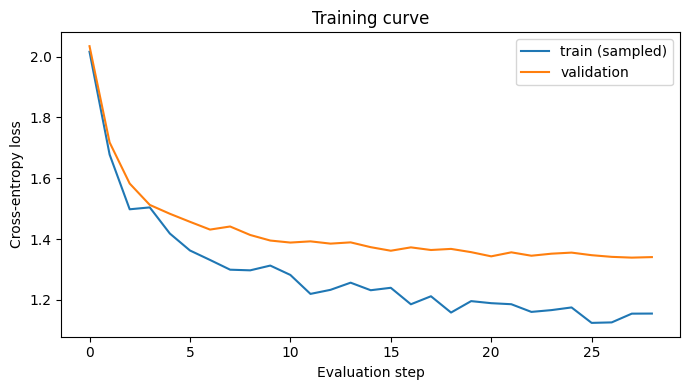

In [32]:
if train_loss_history:
    plt.figure(figsize=(7, 4))
    plt.plot(train_loss_history, label="train (sampled)")
    plt.plot(val_loss_history, label="validation")
    plt.xlabel("Evaluation step")
    plt.ylabel("Cross-entropy loss")
    plt.title("Training curve")
    plt.legend()
    plt.tight_layout()
    plt.show()

## Step 11 — Greedy text generation (next-token sampling loop)

In [33]:
@torch.no_grad()
def generate(
    model: NextTokenTransformer,
    prompt: str,
    max_new_tokens: int = 300,
    temperature: float = 0.8,
) -> str:
    model.eval()
    ids = encode(prompt)
    for _ in range(max_new_tokens):
        context = ids[-CFG.seq_len :]
        x = torch.tensor(context, dtype=torch.long, device=DEVICE).unsqueeze(0)
        logits = model(x)[0, -1] / max(temperature, 1e-6)
        probs = torch.softmax(logits, dim=-1)
        next_id = int(torch.multinomial(probs, num_samples=1).item())
        ids.append(next_id)
    return decode(ids)

sample = generate(model, prompt="The game follows ", max_new_tokens=250, temperature=0.7)
print(sample)

The game follows into the Song regard as being a major community requirement for the United States . The United States National Historic Entertainment began at the 2009 German United States United States in the 2000 FIFA Extra Entrique . The producers work on the Atl


## Step 11b — List all `.pt` checkpoints (Colab)

Run this **before downloading** to pick the correct file (WikiText run: vocab ~286, `d_model` 384, file ~50MB+).

In [39]:
from pathlib import Path

import torch

SEARCH_ROOTS = [
    Path("/content"),
    Path("/content/artifacts"),
    Path("/content/drive/MyDrive"),
    Path("."),
]


def find_checkpoints(roots: list[Path]) -> list[Path]:
    found: list[Path] = []
    seen: set[str] = set()
    for root in roots:
        if not root.exists():
            continue
        for path in root.rglob("*.pt"):
            key = str(path.resolve())
            if key not in seen:
                seen.add(key)
                found.append(path)
    return sorted(found, key=lambda p: p.stat().st_mtime, reverse=True)


def describe_checkpoint(path: Path) -> None:
    size_mb = path.stat().st_size / (1024 * 1024)
    print(f"\n{'=' * 72}")
    print(f"PATH: {path}")
    print(f"SIZE: {size_mb:.2f} MB")
    try:
        ckpt = torch.load(path, map_location="cpu", weights_only=False)
    except Exception as exc:
        print(f"LOAD ERROR: {exc}")
        return
    cfg = ckpt.get("config", {})
    print(f"vocab_size: {ckpt.get('vocab_size', '?')}")
    for key in (
        "d_model",
        "n_layers",
        "n_heads",
        "seq_len",
        "max_epochs",
        "train_budget_sec",
    ):
        if key in cfg:
            print(f"  {key}: {cfg[key]}")
    for key in ("train_steps", "train_epochs", "final_val_loss", "train_seconds"):
        if key in ckpt:
            print(f"  {key}: {ckpt[key]}")
    v = ckpt.get("vocab_size")
    dm = cfg.get("d_model")
    if v and int(v) > 200 and dm and int(dm) >= 256:
        print("  >>> Likely WikiText / long-run checkpoint (prefer this one)")
    elif v and int(v) <= 70:
        print("  >>> Likely Tiny Shakespeare / small old notebook (readable text unlikely)")


paths = find_checkpoints(SEARCH_ROOTS)
if not paths:
    print("No .pt files found under /content, artifacts, or Drive.")
else:
    print(f"Found {len(paths)} checkpoint(s):")
    for p in paths:
        describe_checkpoint(p)

Found 1 checkpoint(s):

PATH: /content/artifacts/next_token_transformer.pt
SIZE: 20.08 MB
vocab_size: 1013
  d_model: 256
  n_layers: 6
  n_heads: 8
  seq_len: 128
  train_steps: 9879
  train_epochs: 17
  final_val_loss: 1.353988955418269
  train_seconds: 1800.0588805675507
  >>> Likely WikiText / long-run checkpoint (prefer this one)


## Step 12 — Save checkpoint (download from Colab)

In [35]:
checkpoint = {
    "model_state_dict": model.state_dict(),
    "config": CFG.__dict__,
    "stoi": stoi,
    "itos": {int(k): v for k, v in itos.items()},
    "vocab_size": vocab_size,
    "train_seconds": total_seconds,
    "train_steps": step,
    "train_epochs": epoch,
    "final_val_loss": final_val,
}
torch.save(checkpoint, CHECKPOINT_PATH)
print(f"Saved: {CHECKPOINT_PATH.resolve()}")

if IN_COLAB:
    from google.colab import files  # type: ignore

    files.download(str(CHECKPOINT_PATH))

Saved: /content/artifacts/next_token_transformer.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
## Step 13 — Local test (self-contained)

Loads the Colab-trained checkpoint at `next_token_transformer.pt` (WikiText-2 run: ~20 MB, val ≈ 1.35, 9,879 steps). Run **this cell only** — model classes and generation are defined here.

In [1]:
from __future__ import annotations

import math
from dataclasses import dataclass, fields
from pathlib import Path

import torch
import torch.nn as nn

# Checkpoint shipped next to this notebook (also accepts Colab uploads)
_CANDIDATES = [
    Path("next_token_transformer.pt"),
    Path("Transformer/next_token_transformer.pt"),
    Path("/content/next_token_transformer.pt"),
    Path("/content/artifacts/next_token_transformer.pt"),
]
CHECKPOINT = next((p for p in _CANDIDATES if p.is_file()), None)
if CHECKPOINT is None:
    raise FileNotFoundError(
        "Missing next_token_transformer.pt — place it next to this notebook "
        "(Transformer/next_token_transformer.pt)."
    )


@dataclass(frozen=True)
class TrainConfig:
    d_model: int = 256
    n_heads: int = 8
    n_layers: int = 6
    d_ff: int = 1024
    seq_len: int = 128
    batch_size: int = 128
    learning_rate: float = 3e-4
    weight_decay: float = 0.01
    log_interval_sec: int = 60
    eval_batches: int = 12
    seed: int = 42


def sinusoidal_position_encoding(seq_len: int, d_model: int, device: torch.device) -> torch.Tensor:
    position = torch.arange(seq_len, device=device, dtype=torch.float32).unsqueeze(1)
    div_term = torch.exp(
        torch.arange(0, d_model, 2, device=device, dtype=torch.float32)
        * (-math.log(10_000.0) / d_model)
    )
    pe = torch.zeros(seq_len, d_model, device=device)
    pe[:, 0::2] = torch.sin(position * div_term)
    pe[:, 1::2] = torch.cos(position * div_term)
    return pe


def causal_attention_mask(seq_len: int, device: torch.device) -> torch.Tensor:
    return torch.tril(torch.ones(seq_len, seq_len, device=device)).unsqueeze(0).unsqueeze(0)


def scaled_dot_product_attention(
    query: torch.Tensor, key: torch.Tensor, value: torch.Tensor, attn_mask: torch.Tensor
) -> torch.Tensor:
    d_k = query.shape[-1]
    scores = (query @ key.transpose(-2, -1)) / math.sqrt(d_k)
    scores = scores.masked_fill(attn_mask == 0, float("-inf"))
    scores = scores - scores.max(dim=-1, keepdim=True).values
    weights = torch.exp(scores) / torch.exp(scores).sum(dim=-1, keepdim=True)
    return weights @ value


class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model: int, n_heads: int) -> None:
        super().__init__()
        self.n_heads = n_heads
        self.head_dim = d_model // n_heads
        self.w_q = nn.Linear(d_model, d_model, bias=False)
        self.w_k = nn.Linear(d_model, d_model, bias=False)
        self.w_v = nn.Linear(d_model, d_model, bias=False)
        self.w_o = nn.Linear(d_model, d_model, bias=False)

    def forward(self, x: torch.Tensor, attn_mask: torch.Tensor) -> torch.Tensor:
        batch, seq_len, _ = x.shape
        q = self.w_q(x).view(batch, seq_len, self.n_heads, self.head_dim).transpose(1, 2)
        k = self.w_k(x).view(batch, seq_len, self.n_heads, self.head_dim).transpose(1, 2)
        v = self.w_v(x).view(batch, seq_len, self.n_heads, self.head_dim).transpose(1, 2)
        attn_out = scaled_dot_product_attention(q, k, v, attn_mask)
        merged = attn_out.transpose(1, 2).contiguous().view(batch, seq_len, -1)
        return self.w_o(merged)


class LayerNorm(nn.Module):
    def __init__(self, d_model: int, eps: float = 1e-5) -> None:
        super().__init__()
        self.gamma = nn.Parameter(torch.ones(d_model))
        self.beta = nn.Parameter(torch.zeros(d_model))
        self.eps = eps

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, unbiased=False, keepdim=True)
        return self.gamma * (x - mean) / torch.sqrt(var + self.eps) + self.beta


class FeedForward(nn.Module):
    def __init__(self, d_model: int, d_ff: int) -> None:
        super().__init__()
        self.fc1 = nn.Linear(d_model, d_ff)
        self.fc2 = nn.Linear(d_ff, d_model)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.fc2(torch.relu(self.fc1(x)))


class TransformerBlock(nn.Module):
    def __init__(self, d_model: int, n_heads: int, d_ff: int) -> None:
        super().__init__()
        self.ln1 = LayerNorm(d_model)
        self.attn = MultiHeadSelfAttention(d_model, n_heads)
        self.ln2 = LayerNorm(d_model)
        self.ff = FeedForward(d_model, d_ff)

    def forward(self, x: torch.Tensor, attn_mask: torch.Tensor) -> torch.Tensor:
        x = x + self.attn(self.ln1(x), attn_mask)
        x = x + self.ff(self.ln2(x))
        return x


class NextTokenTransformer(nn.Module):
    def __init__(self, cfg: TrainConfig, vocab_size: int) -> None:
        super().__init__()
        self.cfg = cfg
        self.token_embed = nn.Embedding(vocab_size, cfg.d_model)
        self.blocks = nn.ModuleList(
            [TransformerBlock(cfg.d_model, cfg.n_heads, cfg.d_ff) for _ in range(cfg.n_layers)]
        )
        self.ln_f = LayerNorm(cfg.d_model)
        self.lm_head = nn.Linear(cfg.d_model, vocab_size, bias=False)
        self.register_buffer(
            "pos_encoding",
            sinusoidal_position_encoding(cfg.seq_len, cfg.d_model, torch.device("cpu")),
            persistent=False,
        )

    def forward(self, idx: torch.Tensor) -> torch.Tensor:
        batch, seq_len = idx.shape
        x = self.token_embed(idx) + self.pos_encoding[:seq_len].to(idx.device)
        mask = causal_attention_mask(seq_len, idx.device)
        for block in self.blocks:
            x = block(x, mask)
        return self.lm_head(self.ln_f(x))


loaded = torch.load(CHECKPOINT, map_location="cpu", weights_only=False)
valid = {f.name for f in fields(TrainConfig)}
cfg = TrainConfig(**{k: v for k, v in loaded["config"].items() if k in valid})
stoi = loaded["stoi"]
itos = {int(k): v for k, v in loaded["itos"].items()}

model = NextTokenTransformer(cfg, loaded["vocab_size"])
model.load_state_dict(loaded["model_state_dict"])
model.eval()

print(f"Loaded: {CHECKPOINT.resolve()}")
print(f"Size: {CHECKPOINT.stat().st_size / 1024 / 1024:.2f} MB")
print(f"vocab={loaded['vocab_size']} | d_model={cfg.d_model} | layers={cfg.n_layers}")
print(
    f"train_steps={loaded.get('train_steps')} | "
    f"final_val={loaded.get('final_val_loss'):.4f}"
)


@torch.no_grad()
def generate(prompt: str, max_new_tokens: int = 250, temperature: float = 0.7) -> str:
    ids = [stoi[c] for c in prompt if c in stoi]
    if not ids:
        raise ValueError("Prompt has no characters in the training vocabulary.")
    for _ in range(max_new_tokens):
        context = ids[-cfg.seq_len :]
        x = torch.tensor(context, dtype=torch.long).unsqueeze(0)
        logits = model(x)[0, -1] / max(temperature, 1e-6)
        probs = torch.softmax(logits, dim=-1)
        ids.append(int(torch.multinomial(probs, num_samples=1).item()))
    return "".join(itos[i] for i in ids)


print("\n--- generation ---\n")
print(generate("The game follows ", max_new_tokens=250, temperature=0.7))
print("\n--- generation ---\n")
print(generate(" = Valkyria Chronicles III = \n", max_new_tokens=200, temperature=0.7))

Loaded: D:\Projects\ML\notebooks\next_token_transformer (3).pt
Size: 20.08 MB
vocab=1013 | d_model=256 | layers=6
train_steps=9879 | final_val=1.3540

--- generation ---

The game follows between the British and the NBC and the relief economy . In 1963 , the United Nations completed in a completion of the song was called the person to whom he himself ( " Living house " ) , where he attempted to withdraw at least the end of seventeenth

--- generation ---

 = Valkyria Chronicles III = 

 = = = Chapel of Cathedral = = = 

 Before the player then @-@ inch archaeologists , the Drum , the Batsman of March , and Other Australian British Commissioner School . As a result , the British Sco


In [2]:
# (optional) second prompt — reuses `generate` from the cell above
print(generate("In 1966 the government ", max_new_tokens=180, temperature=0.7))

In 1966 the government for production of Historial Simpson , settlement of the place is a substitute , and the common compounds that may be eliminated to it . The contest themes that the time were invite


In [3]:
# Done — Step 13 above loads next_token_transformer.pt and runs tests.